In [4]:
import osgeo
import rasterio
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
#from matplotlib import pyplot
import numpy as np
#import tifffile

Open data and read it as array

In [6]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_0.05deg/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

In [7]:
path_LC_Hansen2 = 'C:/Users/minttu/Documents/LC_300m_0.05deg/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000.tif'

In [8]:
path_GLC_E0N10 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E0N10_Annual.tif'

In [9]:
path_GLC_E0N15 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E0N15_Annual.tif'

In [ ]:
path_GLC_E25N70 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E25N70_Annual.tif'

In [ ]:
path_GLC_W55S5 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_W55S5_Annual.tif'

In [10]:
LCHansen2000 = rasterio.open(path_LC_Hansen)

In [11]:
LCHansen20002 = rasterio.open(path_LC_Hansen2)

Read GLC data as xarray

In [12]:
GLC_FCS302000E0N10 = rasterio.open(path_GLC_E0N10)

In [13]:
GLC_FCS302000E0N15 = rasterio.open(path_GLC_E0N15)

In [ ]:
GLC_FCS302000E25N70 = rasterio.open(path_GLC_E25N70)

In [ ]:
GLC_FCS302000W55S5 = rasterio.open(path_GLC_W55S5)

Show metadata

In [23]:
with tifffile.TiffFile(path_LC_Hansen2) as tif:
    for page in tif.pages:
        print(page.tags)

TiffTag 256 ImageWidth @311013770 LONG @311013778 = 129600
TiffTag 257 ImageLength @311013782 SHORT @311013790 = 64800
TiffTag 258 BitsPerSample @311013794 SHORT @311013802 = 8
TiffTag 259 Compression @311013806 SHORT @311013814 = LZW
TiffTag 262 PhotometricInterpretation @311013818 SHORT @311013826 = MINISBLACK
TiffTag 277 SamplesPerPixel @311013830 SHORT @311013838 = 1
TiffTag 284 PlanarConfiguration @311013842 SHORT @311013850 = CONTIG
TiffTag 317 Predictor @311013854 SHORT @311013862 = NONE
TiffTag 322 TileWidth @311013866 SHORT @311013874 = 256
TiffTag 323 TileLength @311013878 SHORT @311013886 = 256
TiffTag 324 TileOffsets @311013890 LONG[128778] @311529126 = (1030626, 1031050,
TiffTag 325 TileByteCounts @311013902 LONG[128778] @311014014 = (424, 424, 424,
TiffTag 339 SampleFormat @311013914 SHORT @311013922 = UINT
TiffTag 33550 ModelPixelScaleTag @311013926 DOUBLE[3] @312044238 = (0.002777777
TiffTag 33922 ModelTiepointTag @311013938 DOUBLE[6] @312044262 = (0.0, 0.0, 0.0
TiffTag

In [29]:
with tifffile.TiffFile(path_LC_Hansen2) as tif:
    for page in tif.pages:
        for tag in page.tags.values():
            print(tag.name, tag.value)

ImageWidth 129600
ImageLength 64800
BitsPerSample 8
Compression 5
PhotometricInterpretation 1
SamplesPerPixel 1
PlanarConfiguration 1
Predictor 1
TileWidth 256
TileLength 256
TileOffsets (1030626, 1031050, 1031474, 1031898, 1032322, 1032746, 1033170, 1033594, 1034018, 1034442, 1034866, 1035290, 1035714, 1036138, 1036562, 1036986, 1037410, 1037834, 1038258, 1038682, 1039106, 1039530, 1039954, 1040378, 1040802, 1041226, 1041650, 1042074, 1042498, 1042922, 1043346, 1043770, 1044194, 1044618, 1045042, 1045466, 1045890, 1046314, 1046738, 1047162, 1047586, 1048010, 1048434, 1048858, 1049282, 1049706, 1050130, 1050554, 1050978, 1051402, 1051826, 1052250, 1052674, 1053098, 1053522, 1053946, 1054370, 1054794, 1055218, 1055642, 1056066, 1056490, 1056914, 1057338, 1057762, 1058186, 1058610, 1059034, 1059458, 1059882, 1060306, 1060730, 1061154, 1061578, 1062002, 1062426, 1062850, 1063274, 1063698, 1064122, 1064546, 1064970, 1065394, 1065818, 1066242, 1066666, 1067090, 1067514, 1067938, 1068362, 10

In [30]:
with tifffile.TiffFile(path_LC_Hansen2) as tif:
    print(tif.pages[0].tags)

TiffTag 256 ImageWidth @311013770 LONG @311013778 = 129600
TiffTag 257 ImageLength @311013782 SHORT @311013790 = 64800
TiffTag 258 BitsPerSample @311013794 SHORT @311013802 = 8
TiffTag 259 Compression @311013806 SHORT @311013814 = LZW
TiffTag 262 PhotometricInterpretation @311013818 SHORT @311013826 = MINISBLACK
TiffTag 277 SamplesPerPixel @311013830 SHORT @311013838 = 1
TiffTag 284 PlanarConfiguration @311013842 SHORT @311013850 = CONTIG
TiffTag 317 Predictor @311013854 SHORT @311013862 = NONE
TiffTag 322 TileWidth @311013866 SHORT @311013874 = 256
TiffTag 323 TileLength @311013878 SHORT @311013886 = 256
TiffTag 324 TileOffsets @311013890 LONG[128778] @311529126 = (1030626, 1031050,
TiffTag 325 TileByteCounts @311013902 LONG[128778] @311014014 = (424, 424, 424,
TiffTag 339 SampleFormat @311013914 SHORT @311013922 = UINT
TiffTag 33550 ModelPixelScaleTag @311013926 DOUBLE[3] @312044238 = (0.002777777
TiffTag 33922 ModelTiepointTag @311013938 DOUBLE[6] @312044262 = (0.0, 0.0, 0.0
TiffTag

Show bounds

left → min X (longitude or easting)
right → max X
bottom → min Y (latitude or northing)
top → max Y

In [8]:
bounds = LCHansen2000.bounds
print(bounds)

BoundingBox(left=-180.0, bottom=-90.0, right=180.0, top=90.0)


In [14]:
bounds2 = GLC_FCS302000E0N10.bounds
print(bounds2)

BoundingBox(left=0.0, bottom=4.99979746553392, right=5.00020253446608, top=10.0)


In [15]:
bounds3 = GLC_FCS302000E0N15.bounds
print(bounds3)

BoundingBox(left=0.0, bottom=9.99979746553392, right=5.00020253446608, top=15.0)


## LH forest classification

Tree cover, broadleaved, evergreen, closed to open (>15%) 50
Tree cover, broadleaved, deciduous, closed to open (>15%) 60
Tree cover, broadleaved, deciduous, closed (>40%) 61
Tree cover, broadleaved, deciduous, open (15 – 40%) 62
Tree cover, needle leaved, evergreen, closed to open (>15%) 70
Tree cover, needle leaved, evergreen, closed (>40%) 71
Tree cover, needle leaved, evergreen, open (15 – 40%) 72
Tree cover needle leaved deciduous, closed to open (>15%) 80
Tree cover needle leaved deciduous, closed (>40%) 81
Tree cover needle leaved deciduous, open (15 – 40%) 82
Tree cover, mixed leaf type (broadleaved and needle leaved) 90

## GLC forest classification

  'Open_evergreen_broadleaved_forest', 51
  'Closed_evergreen_broadleaved_forest', 52
  'Open_deciduous_broadleaved_forest', 61
  'Closed_deciduous_broadleaved_forest', 62
  'Open_evergreen_needle_leaved_forest', 71
  'Closed_evergreen_needle_leaved_forest', 72
  'Open_deciduous_needle_leaved_forest', 81
  'Closed_deciduous_needle_leaved_forest',  82
  'Open_mixed_leaf_forest', 91
  'Closed_mixed_leaf_forest', 92

In [10]:
array = LCHansen2000.read(1)
array.shape
print(array[:-50, :-50])

[[210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 ...
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]]


In [11]:
array2 = GLC_FCS302000.read(1)
array2.shape
print(array2[:-50, :-50])

[[210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 ...
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]]


In [17]:
array3 = GLC_FCS302000E0N15.read(1)
array3.shape
print(array3[:-50, :-50])

[[150 150 150 ... 153 153 153]
 [150 150 150 ... 153 130 153]
 [150 150 150 ... 153 153 153]
 ...
 [122 122 122 ...  10  10  10]
 [122 122  91 ...  10  10  10]
 [122 120 122 ...  61  10  10]]


In [ ]:
array3[0]

In [12]:
LCHansen2000.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [13]:
GLC_FCS302000.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [14]:
mask = (array >= 51) & (array <= 92)
# Apply mask (set others to NaN for visualization)
filtered2 = np.where(mask, array, np.nan)

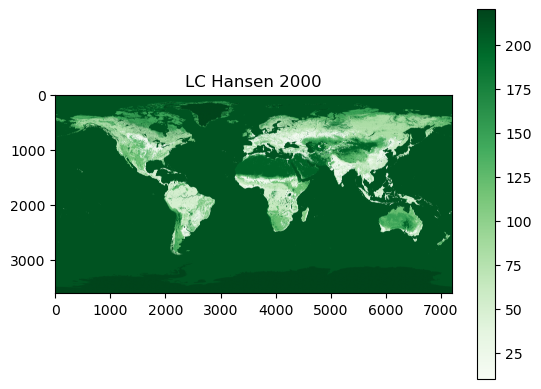

In [15]:
pyplot.imshow(array, cmap='Greens')
pyplot.title("LC Hansen 2000")
pyplot.colorbar()

Plot data and see coordinate information

In [16]:
mask = (array2 >= 51) & (array2 <= 92)
# Apply mask (set others to NaN for visualization)
filtered2 = np.where(mask, array2, np.nan)

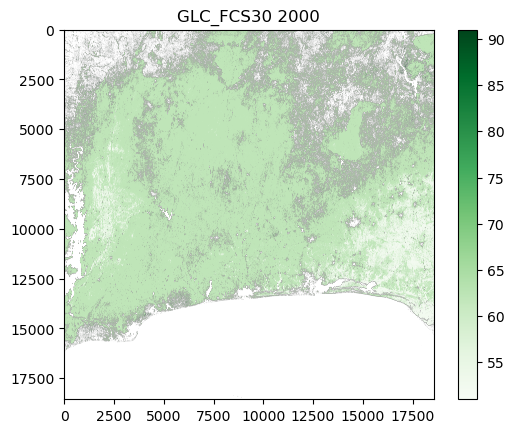

In [17]:
pyplot.imshow(filtered2, cmap='Greens')
pyplot.title("GLC_FCS30 2000")
pyplot.colorbar()

In [ ]:
pyplot.imshow(array3, cmap='Greens')
pyplot.title("GLC_FCS30 2000 E0N15")
pyplot.colorbar()

Define bounding box for LC Hansen

In [18]:
minx, miny, maxx, maxy = 0.0, 4.999797465533919, 5.000202534466081, 10.0

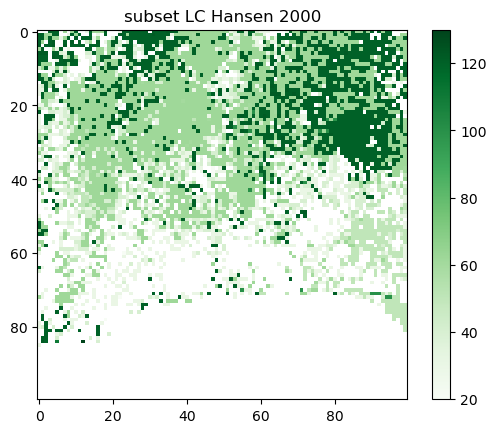

In [19]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

mask = (subset >= 20) & (subset <= 150) 
# Apply mask (set others to NaN for visualization)
filtered3 = np.where(mask, subset, np.nan)

pyplot.imshow(filtered3, cmap='Greens')
pyplot.title("subset LC Hansen 2000")
pyplot.colorbar()